# Report 4: Finding periodic orbits with Newton's method and following them in energy

Report 2 showed that Case 4 is periodic, but it relied on having the exact starting point. Here we use `energy_continuation.continue_to_periodic_orbit` to **find** periodic orbits from an approximate guess, and then follow each orbit as the energy changes.

What the function does:

1. **Section and reduced state.** We choose a section (a line such as $y_1 = 5$, or $x_1 - y_1 = 0$ for particle 1) and a crossing direction. With the energy $E$ fixed, a state on the section is described by 6 numbers $z$. The missing momentum is recovered from $H = E$, so every Newton step stays at the right energy.
2. **Poincaré map $P(z)$.** Leapfrog runs until the next crossing. The crossing time is found by bisection on a fractional leapfrog step instead of interpolation.
3. **Newton's method** solves $P(z) = z$. The Jacobian $DP$ is estimated with central differences, and a damped line search keeps each step safe. The printout shows the residual $|P(z) - z|$ at each iteration.
4. **Stability.** The eigenvalues $\lambda$ of $DP$ at the solution are printed. If all $|\lambda| = 1$, the orbit is linearly stable. If any $|\lambda| > 1$, it is unstable.
5. **Energy continuation.** The energy is set to $E_0 \times$ `energy_ratios`, one value at a time. For each new energy the previous solution, with its momentum rescaled to the new energy, is the starting guess. Each converged orbit is plotted.

In [1]:
import numpy as np
from energy_continuation import Section, continue_to_periodic_orbit
from system import kinetic, inverse_power_potential

## 1. The vertical bouncing orbit (Case 4 family), from $E \approx 11$ down to $E \approx 2.5$

The starting guess is the Case 4 position with momentum $\pm3$. The section is $y_1 = 5$, crossed upward. The energy is lowered step by step to $0.23\,E_0$.

initial energy: 11.0751558171
energy ratios: [1.   0.95 0.9  0.85 0.8  0.75 0.7  0.65 0.6  0.55 0.5  0.45 0.4  0.35
 0.3  0.25 0.24 0.23]

E = 11.0751558171
    Newton  0: ||P(z)-z|| = 5.224e-02
    Newton  1: ||P(z)-z|| = 6.205e-04
    Newton  2: ||P(z)-z|| = 3.541e-07
    Newton  3: ||P(z)-z|| = 2.213e-13
    fixed-point residual = 2.213e-13
    Newton iterations = 4
    lambda = [-0.40749476+0.91320755j -0.40749476-0.91320755j  0.1295806 +0.99156889j
  0.1295806 -0.99156889j  0.94671594+0.32206955j  0.94671594-0.32206955j]
    |lambda| = [1.         1.         1.         1.         0.99999993 0.99999993]
    q* =
 [[3.86109089 5.        ]
 [6.13890911 5.        ]]
    p* =
 [[-4.66282193e-12  2.99872642e+00]
 [ 4.65848437e-12 -2.99872642e+00]]


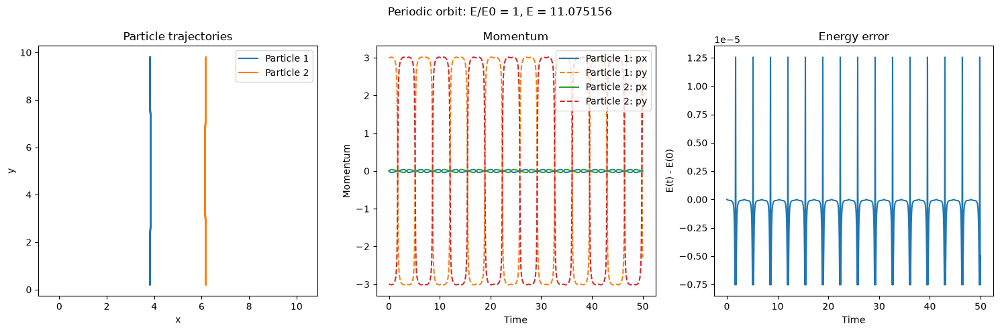


E = 10.5213980262
    Newton  0: ||P(z)-z|| = 2.211e-03
    Newton  1: ||P(z)-z|| = 1.103e-06
    Newton  2: ||P(z)-z|| = 1.169e-12
    fixed-point residual = 1.169e-12
    Newton iterations = 3
    lambda = [-0.46812632+0.88366156j -0.46812632-0.88366156j  0.08255459+0.99658654j
  0.08255459-0.99658654j  0.94274682+0.33350911j  0.94274682-0.33350911j]
    |lambda| = [1.         1.         1.         1.         0.99999995 0.99999995]
    q* =
 [[3.86214144 5.        ]
 [6.13785856 5.        ]]
    p* =
 [[-6.89444209e-12  2.90487214e+00]
 [ 6.88967254e-12 -2.90487214e+00]]


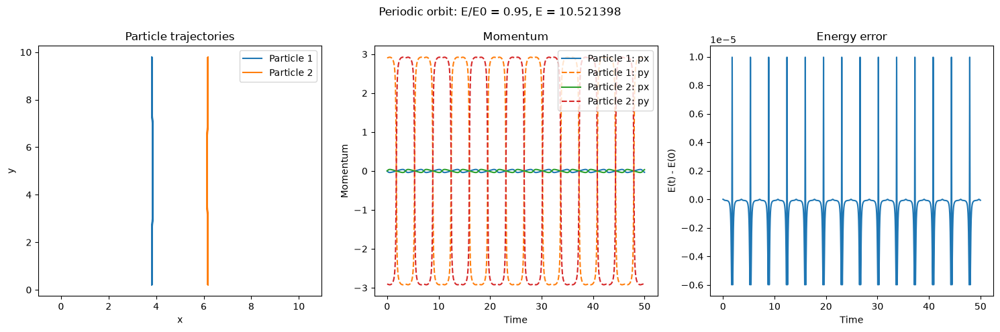


E = 9.9676402354
    Newton  0: ||P(z)-z|| = 2.518e-03
    Newton  1: ||P(z)-z|| = 1.402e-06
    Newton  2: ||P(z)-z|| = 1.165e-12
    fixed-point residual = 1.165e-12
    Newton iterations = 3
    lambda = [-0.53271963+0.8462918j  -0.53271963-0.8462918j   0.03050154+0.99953472j
  0.03050154-0.99953472j  0.93818102+0.34614488j  0.93818102-0.34614488j]
    |lambda| = [1.         1.         1.         1.         0.99999996 0.99999996]
    q* =
 [[3.86329014 5.        ]
 [6.13670986 5.        ]]
    p* =
 [[-5.02407415e-12  2.80787700e+00]
 [ 5.01624147e-12 -2.80787700e+00]]


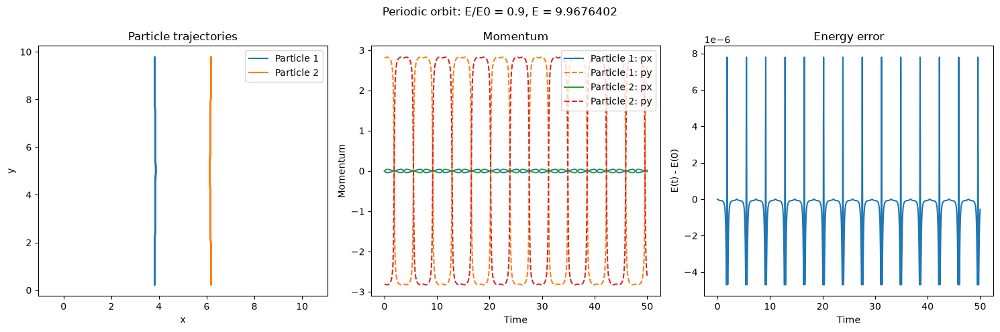


E = 9.4138824445
    Newton  0: ||P(z)-z|| = 2.886e-03
    Newton  1: ||P(z)-z|| = 1.809e-06
    Newton  2: ||P(z)-z|| = 2.817e-12
    fixed-point residual = 2.817e-12
    Newton iterations = 3
    lambda = [-0.60119267+0.79910411j -0.60119267-0.79910411j -0.02735217+0.99962586j
 -0.02735217-0.99962586j  0.93287932+0.36018929j  0.93287932-0.36018929j]
    |lambda| = [1.         1.         1.         1.         1.00000007 1.00000007]
    q* =
 [[3.86455267 5.        ]
 [6.13544733 5.        ]]
    p* =
 [[-5.04235084e-12  2.70740253e+00]
 [ 5.03561817e-12 -2.70740253e+00]]


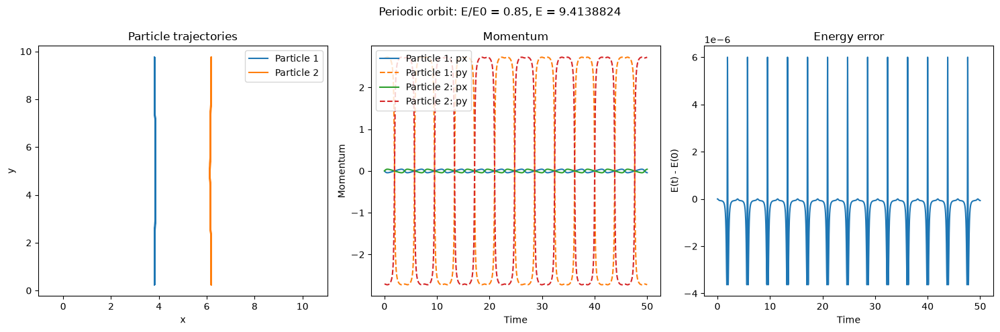


E = 8.8601246537
    Newton  0: ||P(z)-z|| = 3.328e-03
    Newton  1: ||P(z)-z|| = 2.374e-06
    Newton  2: ||P(z)-z|| = 2.142e-12
    fixed-point residual = 2.142e-12
    Newton iterations = 3
    lambda = [-0.67315169+0.73950444j -0.67315169-0.73950444j -0.09191746+0.99576663j
 -0.09191746-0.99576663j  0.92665664+0.37590904j  0.92665664-0.37590904j]
    |lambda| = [1.         1.         1.         1.         1.00000007 1.00000007]
    q* =
 [[3.8659485 5.       ]
 [6.1340515 5.       ]]
    p* =
 [[-4.35073000e-12  2.60304463e+00]
 [ 4.36063597e-12 -2.60304463e+00]]


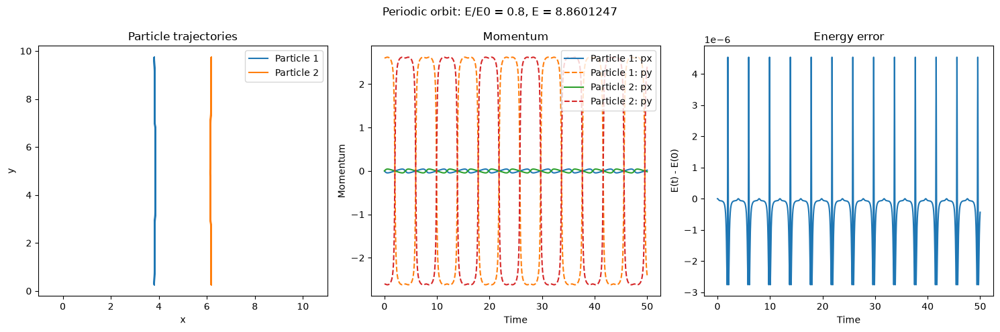


E = 8.3063668628
    Newton  0: ||P(z)-z|| = 3.862e-03
    Newton  1: ||P(z)-z|| = 3.179e-06
    Newton  2: ||P(z)-z|| = 7.602e-13
    fixed-point residual = 7.602e-13
    Newton iterations = 3
    lambda = [-0.74764779+0.66409546j -0.74764779-0.66409546j -0.16425629+0.98641769j
 -0.16425629-0.98641769j  0.9192626 +0.39364509j  0.9192626 -0.39364509j]
    |lambda| = [1.         1.         1.         1.         1.00000009 1.00000009]
    q* =
 [[3.86750214 5.        ]
 [6.13249786 5.        ]]
    p* =
 [[-1.89979303e-12  2.49431431e+00]
 [ 1.90390246e-12 -2.49431431e+00]]


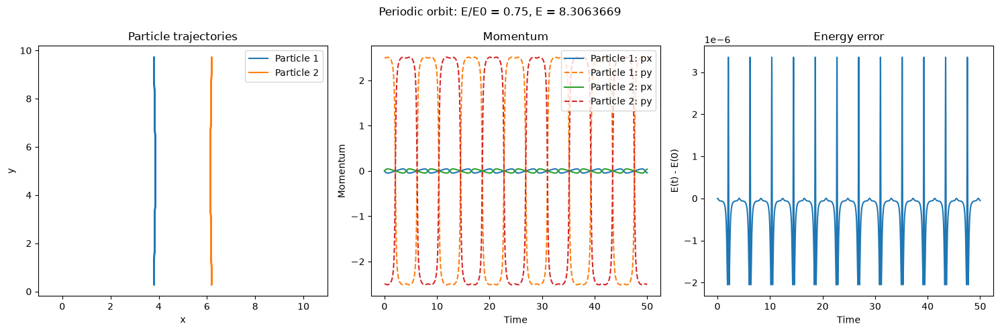


E = 7.7526090720
    Newton  0: ||P(z)-z|| = 4.512e-03
    Newton  1: ||P(z)-z|| = 4.358e-06
    Newton  2: ||P(z)-z|| = 1.887e-12
    fixed-point residual = 1.887e-12
    Newton iterations = 3
    lambda = [-0.82274601+0.56840918j -0.82274601-0.56840918j -0.24557908+0.96937656j
 -0.24557908-0.96937656j  0.91035014+0.41383852j  0.91035014-0.41383852j]
    |lambda| = [1.         1.         1.         1.         0.99999985 0.99999985]
    q* =
 [[3.86924512 5.        ]
 [6.13075488 5.        ]]
    p* =
 [[-1.41509822e-12  2.38061038e+00]
 [ 1.41611031e-12 -2.38061038e+00]]


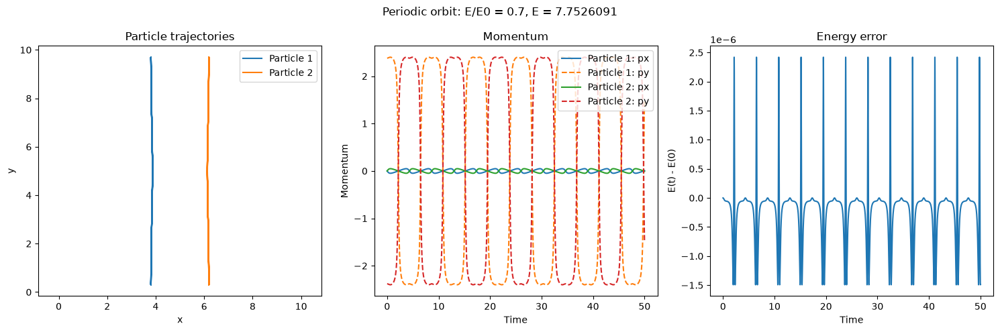


E = 7.1988512811
    Newton  0: ||P(z)-z|| = 5.304e-03
    Newton  1: ||P(z)-z|| = 6.146e-06
    Newton  2: ||P(z)-z|| = 8.511e-13
    fixed-point residual = 8.511e-13
    Newton iterations = 3
    lambda = [-0.89474439+0.44657863j -0.89474439-0.44657863j -0.33719859+0.94143354j
 -0.33719859-0.94143354j  0.89942553+0.43707414j  0.89942553-0.43707414j]
    |lambda| = [1.         1.         1.         1.         1.00000005 1.00000005]
    q* =
 [[3.87121888 5.        ]
 [6.12878112 5.        ]]
    p* =
 [[-4.68391374e-12  2.26117963e+00]
 [ 4.67953911e-12 -2.26117963e+00]]


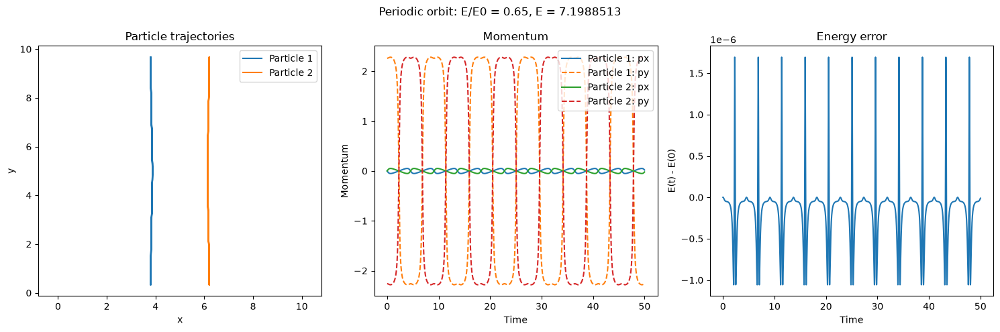


E = 6.6450934903
    Newton  0: ||P(z)-z|| = 6.268e-03
    Newton  1: ||P(z)-z|| = 8.971e-06
    Newton  2: ||P(z)-z|| = 1.835e-12
    fixed-point residual = 1.835e-12
    Newton iterations = 3
    lambda = [ 0.88576471+0.46413446j  0.88576471-0.46413446j -0.44037502+0.89781392j
 -0.44037502-0.89781392j -0.9567196 +0.29101134j -0.9567196 -0.29101134j]
    |lambda| = [0.99999996 0.99999996 1.         1.         1.         1.        ]
    q* =
 [[3.87347961 5.        ]
 [6.12652039 5.        ]]
    p* =
 [[-1.34056335e-12  2.13505683e+00]
 [ 1.33999055e-12 -2.13505683e+00]]


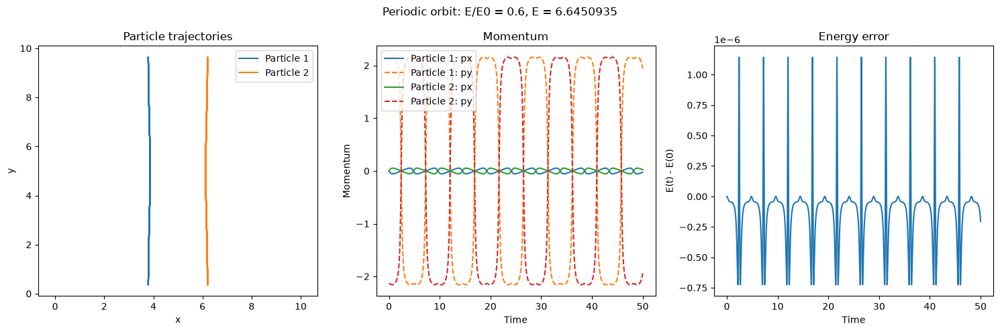


E = 6.0913356994
    Newton  0: ||P(z)-z|| = 7.426e-03
    Newton  1: ||P(z)-z|| = 1.367e-05
    Newton  2: ||P(z)-z|| = 5.847e-12
    fixed-point residual = 5.847e-12
    Newton iterations = 3
    lambda = [ 0.86826452+0.49610143j  0.86826452-0.49610143j -0.55589515+0.83125242j
 -0.55589515-0.83125242j -0.99572789+0.0923362j  -0.99572789-0.0923362j ]
    |lambda| = [0.99999996 0.99999996 1.         1.         1.         1.        ]
    q* =
 [[3.87610639 5.        ]
 [6.12389361 5.        ]]
    p* =
 [[-2.05691640e-12  2.00097037e+00]
 [ 2.05744947e-12 -2.00097037e+00]]


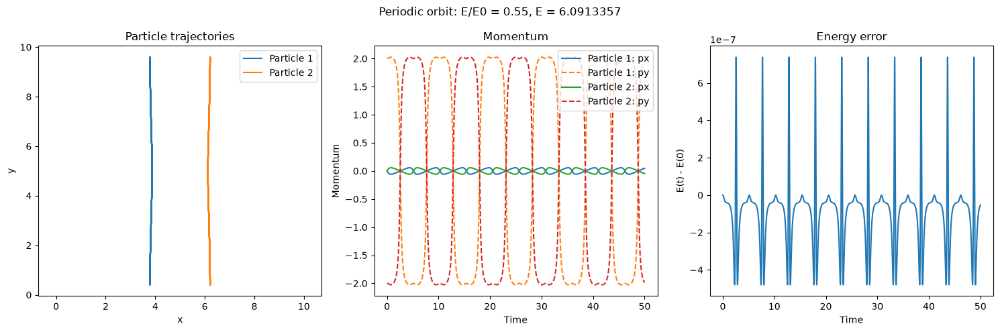


E = 5.5375779086
    Newton  0: ||P(z)-z|| = 8.760e-03
    Newton  1: ||P(z)-z|| = 2.202e-05
    Newton  2: ||P(z)-z|| = 1.821e-11
    fixed-point residual = 1.821e-11
    Newton iterations = 3
    lambda = [ 0.84516784+0.53450113j  0.84516784-0.53450113j -0.68298695+0.73043058j
 -0.68298695-0.73043058j -0.98721669+0.15938384j -0.98721669-0.15938384j]
    |lambda| = [1.00000007 1.00000007 1.         1.         1.         1.        ]
    q* =
 [[3.87921671 5.        ]
 [6.12078329 5.        ]]
    p* =
 [[ 1.96788592e-12  1.85718544e+00]
 [-1.97113191e-12 -1.85718544e+00]]


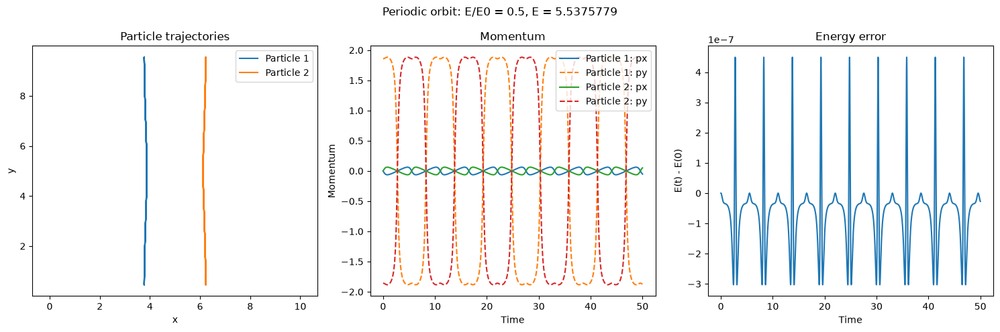


E = 4.9838201177
    Newton  0: ||P(z)-z|| = 1.012e-02
    Newton  1: ||P(z)-z|| = 3.816e-05
    Newton  2: ||P(z)-z|| = 3.386e-11
    fixed-point residual = 3.386e-11
    Newton iterations = 3
    lambda = [ 0.81351351+0.58154599j  0.81351351-0.58154599j -0.81650265+0.57734169j
 -0.81650265-0.57734169j -0.88344413+0.46853652j -0.88344413-0.46853652j]
    |lambda| = [0.99999999 0.99999999 1.         1.         1.         1.        ]
    q* =
 [[3.88299892 5.        ]
 [6.11700108 5.        ]]
    p* =
 [[ 3.06031416e-12  1.70122590e+00]
 [-3.04632576e-12 -1.70122590e+00]]


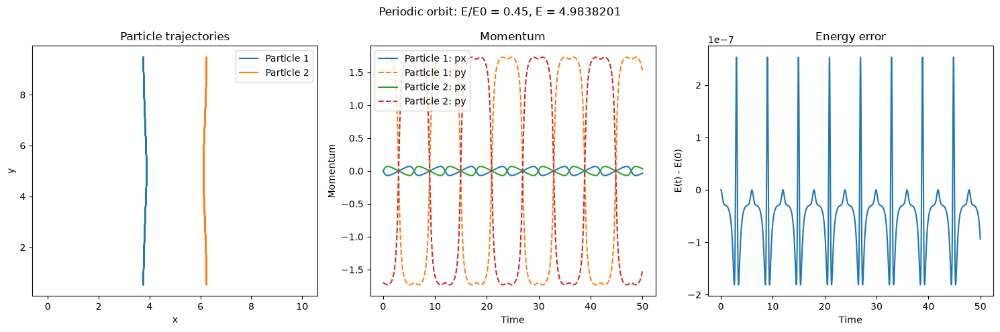


E = 4.4300623268
    Newton  0: ||P(z)-z|| = 1.087e-02
    Newton  1: ||P(z)-z|| = 7.346e-05
    Newton  2: ||P(z)-z|| = 6.699e-10
    fixed-point residual = 6.699e-10
    Newton iterations = 3
    lambda = [ 0.76793763+0.64052466j  0.76793763-0.64052466j -0.58889008+0.80821314j
 -0.58889008-0.80821314j -0.93928331+0.34314261j -0.93928331-0.34314261j]
    |lambda| = [1.00000002 1.00000002 1.         1.         1.         1.        ]
    q* =
 [[3.88779229 5.        ]
 [6.11220771 5.        ]]
    p* =
 [[-9.75385103e-11  1.52933359e+00]
 [ 9.75134362e-11 -1.52933359e+00]]


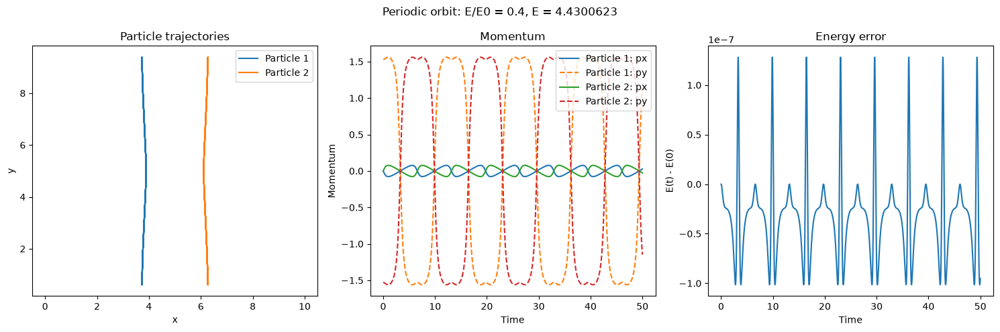


E = 3.8763045360
    Newton  0: ||P(z)-z|| = 8.593e-03
    Newton  1: ||P(z)-z|| = 1.689e-04
    Newton  2: ||P(z)-z|| = 7.696e-09
    Newton  3: ||P(z)-z|| = 1.462e-13
    fixed-point residual = 1.462e-13
    Newton iterations = 4
    lambda = [ 0.69773322+0.71635764j  0.69773322-0.71635764j  0.08942306+0.99599373j
  0.08942306-0.99599373j -0.99987301+0.01593607j -0.99987301-0.01593607j]
    |lambda| = [0.99999996 0.99999996 0.99999999 0.99999999 1.         1.        ]
    q* =
 [[3.8943343 5.       ]
 [6.1056657 5.       ]]
    p* =
 [[-1.67539492e-12  1.33527416e+00]
 [ 1.66840029e-12 -1.33527416e+00]]


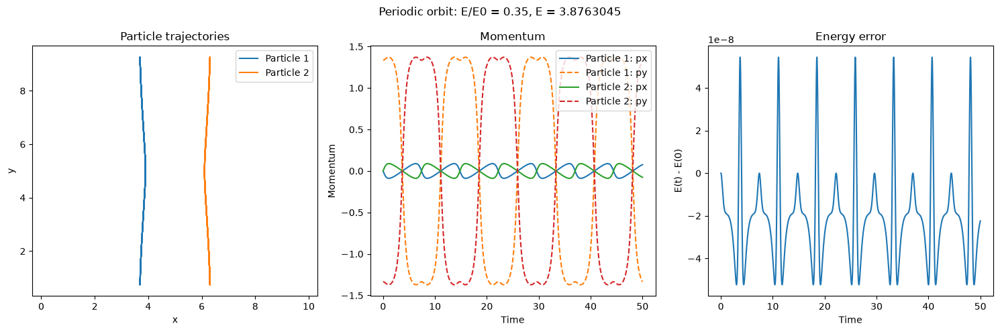


E = 3.3225467451
    Newton  0: ||P(z)-z|| = 7.617e-03
    Newton  1: ||P(z)-z|| = 5.909e-04
    Newton  2: ||P(z)-z|| = 4.023e-07
    Newton  3: ||P(z)-z|| = 7.687e-13
    fixed-point residual = 7.687e-13
    Newton iterations = 4
    lambda = [ 2.59163867+0.j         -0.84069364+0.54151104j -0.84069364-0.54151104j
  0.57828927+0.81583183j  0.57828927-0.81583183j  0.38585625+0.j        ]
    |lambda| = [2.59163867 1.         1.         1.00000002 1.00000002 0.38585625]
    q* =
 [[3.90483944 5.        ]
 [6.09516056 5.        ]]
    p* =
 [[-2.16126139e-13  1.10710368e+00]
 [ 2.16010720e-13 -1.10710368e+00]]


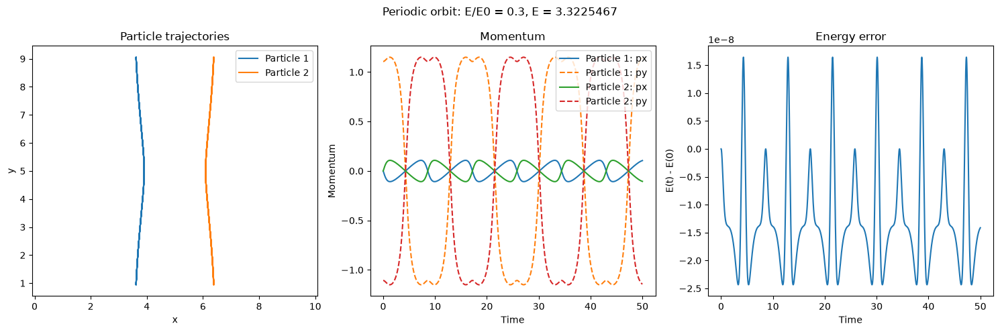


E = 2.7687889543
    Newton  0: ||P(z)-z|| = 9.497e-02
    Newton  1: ||P(z)-z|| = 7.713e-03
    Newton  2: ||P(z)-z|| = 6.269e-04
    Newton  3: ||P(z)-z|| = 1.165e-07
    Newton  4: ||P(z)-z|| = 2.648e-13
    fixed-point residual = 2.648e-13
    Newton iterations = 5
    lambda = [6.04370166+0.j         0.16546152+0.j         0.04470164+0.99900038j
 0.04470164-0.99900038j 0.33769808+0.94125463j 0.33769808-0.94125463j]
    |lambda| = [6.04370166 0.16546152 1.         1.         1.00000014 1.00000014]
    q* =
 [[3.93208664 5.        ]
 [6.06791336 5.        ]]
    p* =
 [[-7.45096195e-13  8.13847522e-01]
 [ 7.41375619e-13 -8.13847522e-01]]


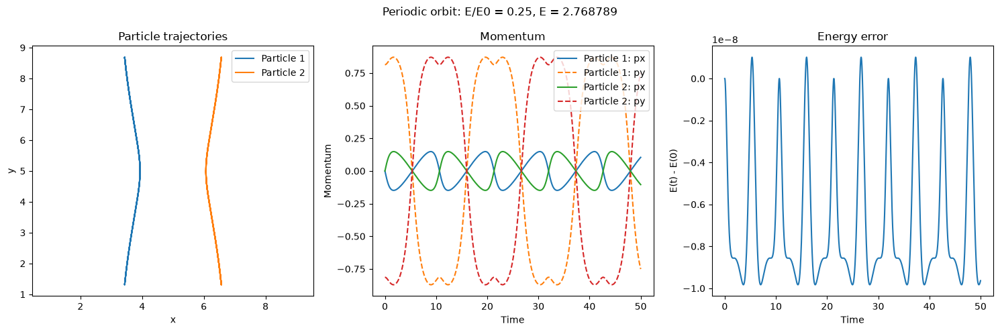


E = 2.6580373961
    Newton  0: ||P(z)-z|| = 4.831e-02
    Newton  1: ||P(z)-z|| = 2.960e-03
    Newton  2: ||P(z)-z|| = 3.644e-05
    Newton  3: ||P(z)-z|| = 4.683e-09
    Newton  4: ||P(z)-z|| = 6.132e-13
    fixed-point residual = 6.132e-13
    Newton iterations = 5
    lambda = [5.2106779 +0.j         0.1919136 +0.j         0.25739306+0.96630668j
 0.25739306-0.96630668j 0.40263903+0.91535885j 0.40263903-0.91535885j]
    |lambda| = [5.2106779  0.1919136  0.99999989 0.99999989 1.         1.        ]
    q* =
 [[3.94637824 5.        ]
 [6.05362176 5.        ]]
    p* =
 [[-1.18537520e-14  7.39127368e-01]
 [ 2.96701862e-15 -7.39127368e-01]]


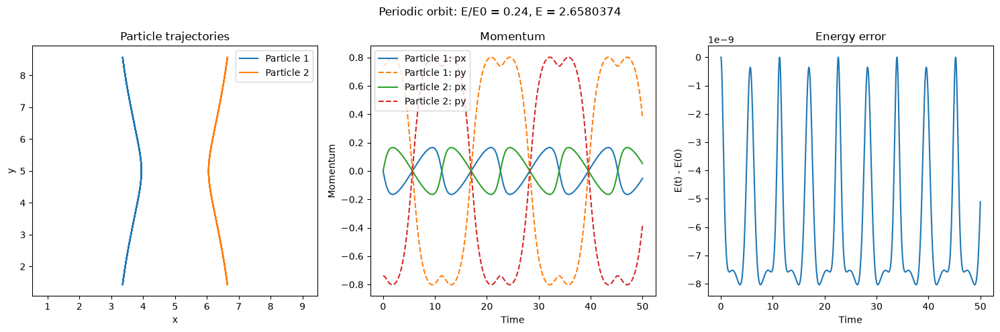


E = 2.5472858379
    Newton  0: ||P(z)-z|| = 6.282e-02
    Newton  1: ||P(z)-z|| = 3.375e-02
    Newton  2: ||P(z)-z|| = 2.399e-02
    Newton  3: ||P(z)-z|| = 1.504e-04
    Newton  4: ||P(z)-z|| = 9.974e-07
    Newton  5: ||P(z)-z|| = 1.995e-11
    fixed-point residual = 1.995e-11
    Newton iterations = 6
    lambda = [0.15142355+0.98846903j 0.15142355-0.98846903j 0.57625387+0.81727086j
 0.57625387-0.81727086j 0.86004508+0.51021805j 0.86004508-0.51021805j]
    |lambda| = [1.00000006 1.00000006 1.00000009 1.00000009 1.         1.        ]
    q* =
 [[3.98550117 5.        ]
 [6.01449883 5.        ]]
    p* =
 [[ 0.05591962  0.64572123]
 [-0.05591962 -0.64572123]]


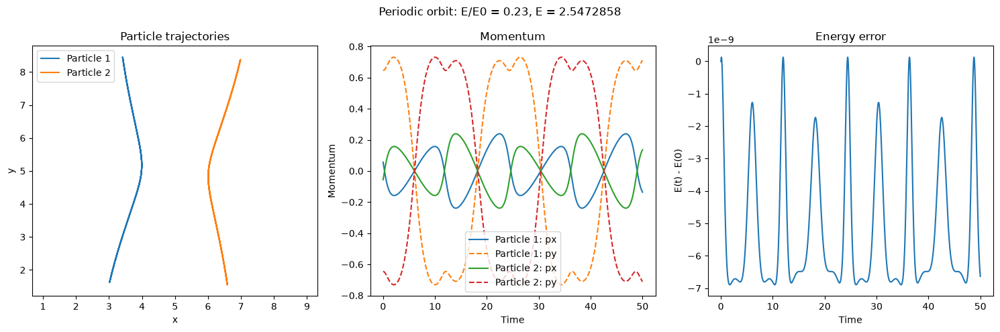

In [2]:
parameters = {
    "k": 1.0,
    "alpha": 1.0,
    "beta": 1.0,
    "C": 1.0,
    "Lx": 10.0,
    "Ly": 10.0,
}

X_STAR = 3.8351644331875563
q_guess = np.array([
    [X_STAR, 5.0],
    [10.0 - X_STAR, 5.0],
])
p_guess = np.array([
    [0.0, 3.0],
    [0.0, -3.0],
])

results = continue_to_periodic_orbit(
    initial_condition={"q": q_guess, "p": p_guess},
    parameters=parameters,
    section=Section(particle=0, coordinate=1, value=5.0, direction=1),
    energy_ratios=np.array([
        1.00, 0.95, 0.90, 0.85, 0.80, 0.75, 0.70, 0.65,
        0.60, 0.55, 0.50, 0.45, 0.40, 0.35, 0.30,
        0.25, 0.24, 0.23,
    ]),
    h=5e-4,
    max_return_steps=100000,
    nsteps=100000,
)

**Result.** Newton converges at every energy in 3–6 iterations, with final residuals of $10^{-9}$–$10^{-13}$, so each orbit is a genuine periodic orbit. As $E$ decreases, $x_1^*$ moves slowly from $3.861$ to about $3.95$ and the vertical momentum falls. The stability changes along the way:

| Energy range | Multipliers | Stability |
|---|---|---|
| $E \approx 11.1$ down to $3.88$ | all $\lvert\lambda\rvert = 1$ | **stable** |
| $E \approx 3.32,\ 2.77,\ 2.66$ | one real pair, e.g. $\lambda \approx 6.04$ and $1/6.04$ | **unstable** |
| $E \approx 2.55$ | all $\lvert\lambda\rvert = 1$ | stable, but a different orbit (see below) |

- The vertical orbit is **stable at high energy and loses stability somewhere between $E \approx 3.9$ and $E \approx 3.3$**. At $E \approx 3.88$ one pair of multipliers is already very close to $-1$.
- At the last step ($E \approx 2.55$) Newton did not stay on the vertical orbit. It converged to a new orbit with nonzero $p_x$, and the paths curve into "S" shapes (see the last figure). This is probably a different branch of periodic orbits, not a continuation of the vertical one.

## 2. The "circular" orbit (Case 3 family), from $E \approx 2.0$ up to $E \approx 4.0$

Case 3 from Report 1 looked almost periodic, but Newton starting directly from it stalls. We therefore use a nearby symmetric guess at the **same energy**: position $(3.6, 3.6)$, with the momentum chosen so that the energy matches. The section is the diagonal $x_1 = y_1$, crossed with $x_1 - y_1$ increasing. Then the energy is raised to $2E_0$.

initial energy: 2.0076519650
energy ratios: [1.   1.05 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45 1.5  1.55 1.6  1.65
 1.7  1.75 1.8  1.85 1.9  1.95 2.  ]

E = 2.0076519650
    Newton  0: ||P(z)-z|| = 2.744e-02
    Newton  1: ||P(z)-z|| = 6.962e-04
    Newton  2: ||P(z)-z|| = 3.991e-07
    Newton  3: ||P(z)-z|| = 1.121e-13
    fixed-point residual = 1.121e-13
    Newton iterations = 4
    lambda = [-0.22062348+0.97535906j -0.22062348-0.97535906j -0.78095788+0.62458371j
 -0.78095788-0.62458371j -0.78095787+0.62458371j -0.78095787-0.62458371j]
    |lambda| = [1.00000001 1.00000001 1.00000001 1.00000001 1.         1.        ]
    q* =
 [[3.5889166 3.5889166]
 [6.4110834 6.4110834]]
    p* =
 [[ 0.09652827 -0.09652827]
 [-0.09652827  0.09652827]]


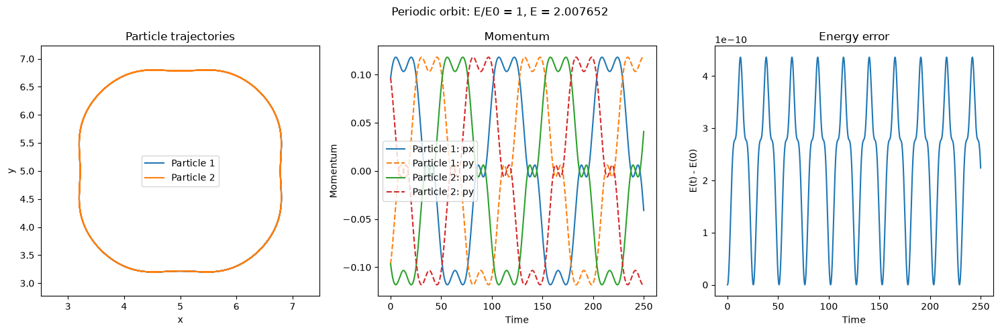


E = 2.1080345632
    Newton  0: ||P(z)-z|| = 1.625e-03
    Newton  1: ||P(z)-z|| = 1.141e-03
    Newton  2: ||P(z)-z|| = 9.389e-04
    Newton  3: ||P(z)-z|| = 7.419e-04
    Newton  4: ||P(z)-z|| = 6.015e-04
    Newton  5: ||P(z)-z|| = 9.525e-06
    Newton  6: ||P(z)-z|| = 9.226e-10
    fixed-point residual = 9.226e-10
    Newton iterations = 7
    lambda = [ 0.99948973+0.03194162j  0.99948973-0.03194162j -0.53088259+0.84744538j
 -0.53088259-0.84744538j -0.53088258+0.84744538j -0.53088258-0.84744538j]
    |lambda| = [1. 1. 1. 1. 1. 1.]
    q* =
 [[3.53604232 3.53604232]
 [6.46395768 6.46395768]]
    p* =
 [[ 0.24135581 -0.24135581]
 [-0.24135581  0.24135581]]


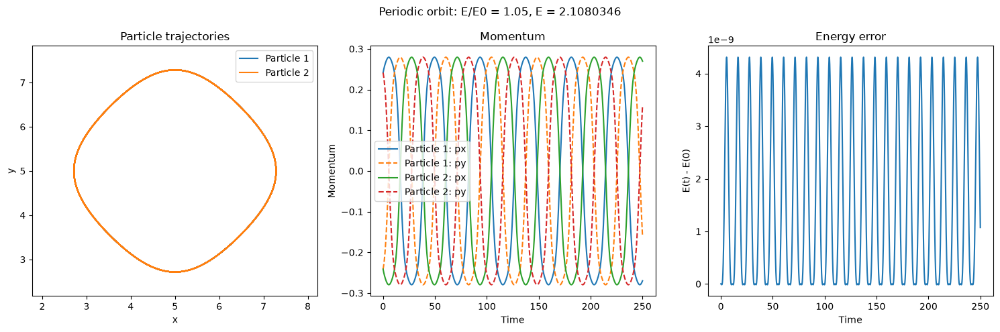


E = 2.2084171615
    Newton  0: ||P(z)-z|| = 4.981e-01
    Newton  1: ||P(z)-z|| = 1.120e-01
    Newton  2: ||P(z)-z|| = 1.820e-03
    Newton  3: ||P(z)-z|| = 4.295e-06
    Newton  4: ||P(z)-z|| = 1.250e-12
    fixed-point residual = 1.250e-12
    Newton iterations = 5
    lambda = [-0.64338368+0.76554387j -0.64338368-0.76554387j -0.93508096+0.35443419j
 -0.93508096-0.35443419j -0.93508096+0.35443419j -0.93508096-0.35443419j]
    |lambda| = [0.99999999 0.99999999 1.         1.         1.         1.        ]
    q* =
 [[3.3649514 3.3649514]
 [6.6350486 6.6350486]]
    p* =
 [[ 0.31670124 -0.31670124]
 [-0.31670124  0.31670124]]


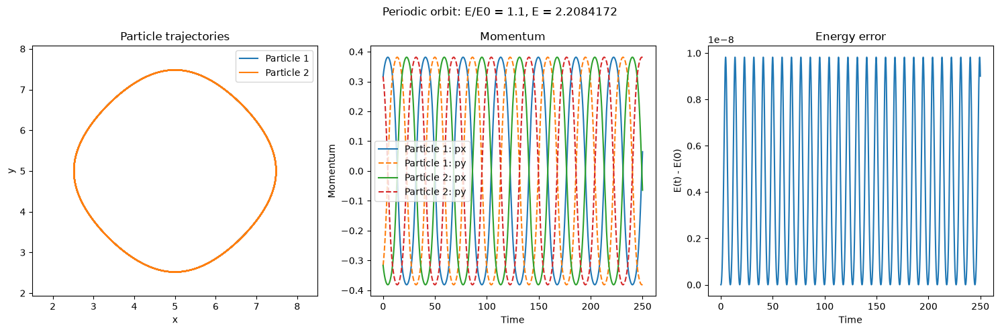


E = 2.3087997597
    Newton  0: ||P(z)-z|| = 4.631e-01
    Newton  1: ||P(z)-z|| = 3.191e-02
    Newton  2: ||P(z)-z|| = 1.722e-04
    Newton  3: ||P(z)-z|| = 3.208e-08
    Newton  4: ||P(z)-z|| = 9.463e-14
    fixed-point residual = 9.463e-14
    Newton iterations = 5
    lambda = [-0.99972321+0.02352607j -0.99972321-0.02352607j -0.6185593 +0.78573811j
 -0.6185593 -0.78573811j -0.6185593 +0.78573812j -0.6185593 -0.78573812j]
    |lambda| = [0.99999999 0.99999999 1.         1.         1.         1.        ]
    q* =
 [[3.24553815 3.24553815]
 [6.75446185 6.75446185]]
    p* =
 [[ 0.37591266 -0.37591266]
 [-0.37591266  0.37591266]]


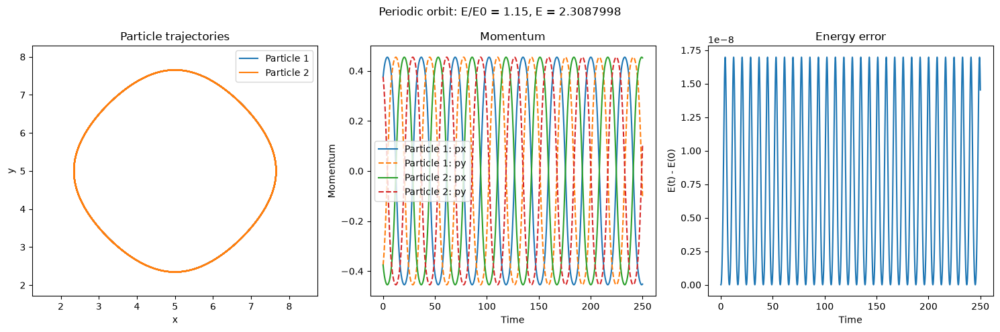


E = 2.4091823580
    Newton  0: ||P(z)-z|| = 3.573e-01
    Newton  1: ||P(z)-z|| = 2.051e-02
    Newton  2: ||P(z)-z|| = 5.148e-05
    Newton  3: ||P(z)-z|| = 7.606e-09
    Newton  4: ||P(z)-z|| = 5.636e-14
    fixed-point residual = 5.636e-14
    Newton iterations = 5
    lambda = [-0.91170548+0.41084443j -0.91170548-0.41084443j -0.36166992+0.93230622j
 -0.36166992-0.93230622j -0.3616699 +0.93230622j -0.3616699 -0.93230622j]
    |lambda| = [1.00000001 1.00000001 1.00000001 1.00000001 1.         1.        ]
    q* =
 [[3.15056712 3.15056712]
 [6.84943288 6.84943288]]
    p* =
 [[ 0.42685546 -0.42685546]
 [-0.42685546  0.42685546]]


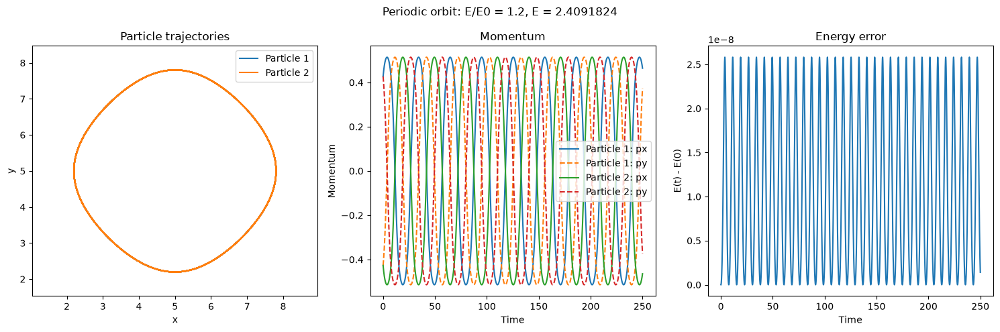


E = 2.5095649562
    Newton  0: ||P(z)-z|| = 2.752e-01
    Newton  1: ||P(z)-z|| = 1.430e-02
    Newton  2: ||P(z)-z|| = 2.211e-05
    Newton  3: ||P(z)-z|| = 2.369e-09
    Newton  4: ||P(z)-z|| = 5.674e-14
    fixed-point residual = 5.674e-14
    Newton iterations = 5
    lambda = [-0.76380023+0.64545272j -0.76380023-0.64545272j -0.17784382+0.98405873j
 -0.17784382-0.98405873j -0.17784382+0.98405872j -0.17784382-0.98405872j]
    |lambda| = [1.00000001 1.00000001 1.         1.         1.         1.        ]
    q* =
 [[3.07191842 3.07191842]
 [6.92808158 6.92808158]]
    p* =
 [[ 0.4726077 -0.4726077]
 [-0.4726077  0.4726077]]


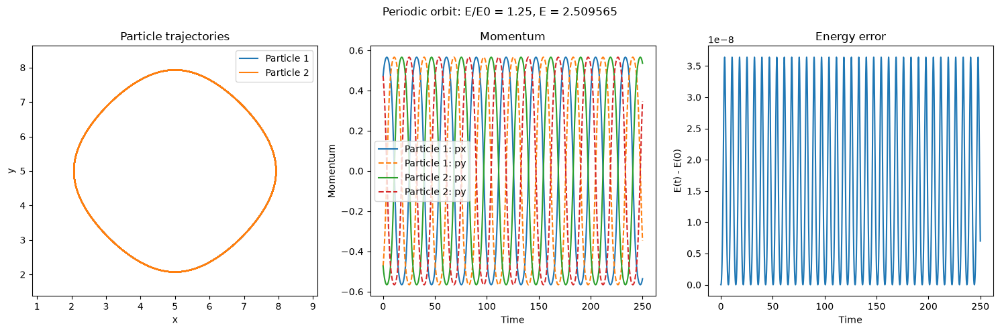


E = 2.6099475545
    Newton  0: ||P(z)-z|| = 2.162e-01
    Newton  1: ||P(z)-z|| = 1.036e-02
    Newton  2: ||P(z)-z|| = 1.177e-05
    Newton  3: ||P(z)-z|| = 6.573e-10
    fixed-point residual = 6.573e-10
    Newton iterations = 4
    lambda = [-0.62662474+0.77932113j -0.62662474-0.77932113j -0.04273621+0.9990864j
 -0.04273621-0.9990864j  -0.04273622+0.99908639j -0.04273622-0.99908639j]
    |lambda| = [1.         1.         1.00000001 1.00000001 1.         1.        ]
    q* =
 [[3.00531056 3.00531056]
 [6.99468944 6.99468944]]
    p* =
 [[ 0.51471378 -0.51471378]
 [-0.51471378  0.51471378]]


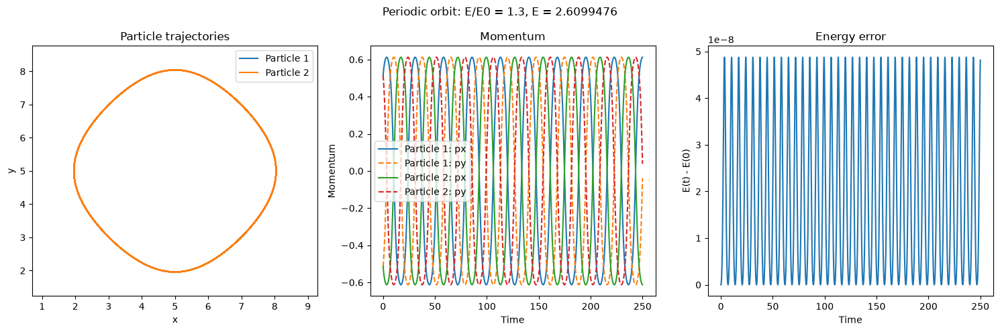


E = 2.7103301527
    Newton  0: ||P(z)-z|| = 1.733e-01
    Newton  1: ||P(z)-z|| = 7.725e-03
    Newton  2: ||P(z)-z|| = 8.026e-06
    Newton  3: ||P(z)-z|| = 1.568e-10
    fixed-point residual = 1.568e-10
    Newton iterations = 4
    lambda = [-0.50996393+0.86019576j -0.50996393-0.86019576j  0.06062728+0.99816048j
  0.06062728-0.99816048j  0.06062727+0.99816046j  0.06062727-0.99816046j]
    |lambda| = [0.99999998 0.99999998 1.         1.         0.99999998 0.99999998]
    q* =
 [[2.94803971 2.94803971]
 [7.05196029 7.05196029]]
    p* =
 [[ 0.55406581 -0.55406581]
 [-0.55406581  0.55406581]]


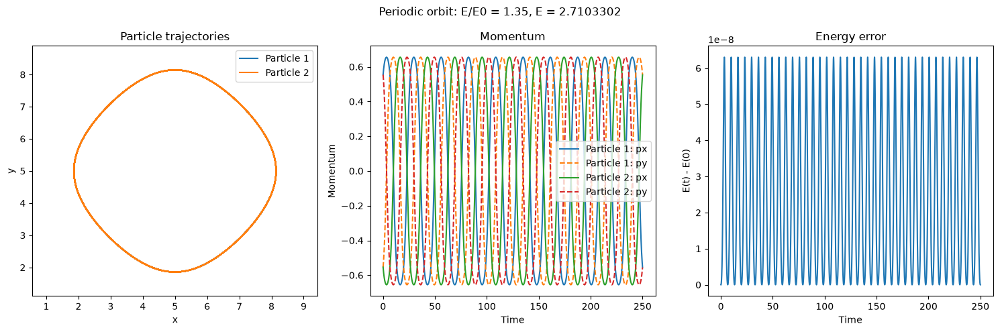


E = 2.8107127510
    Newton  0: ||P(z)-z|| = 1.413e-01
    Newton  1: ||P(z)-z|| = 5.883e-03
    Newton  2: ||P(z)-z|| = 6.280e-06
    Newton  3: ||P(z)-z|| = 3.090e-11
    fixed-point residual = 3.090e-11
    Newton iterations = 4
    lambda = [-0.41188526+0.9112357j  -0.41188526-0.9112357j   0.14257618+0.98978383j
  0.14257618-0.98978383j  0.14257619+0.98978384j  0.14257619-0.98978384j]
    |lambda| = [0.99999998 0.99999998 0.99999999 0.99999999 1.00000001 1.00000001]
    q* =
 [[2.89823893 2.89823893]
 [7.10176107 7.10176107]]
    p* =
 [[ 0.59123008 -0.59123008]
 [-0.59123008  0.59123008]]


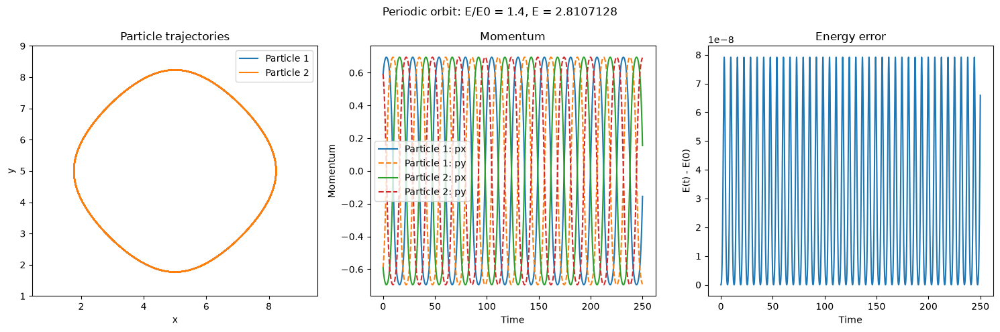


E = 2.9110953492
    Newton  0: ||P(z)-z|| = 1.169e-01
    Newton  1: ||P(z)-z|| = 4.554e-03
    Newton  2: ||P(z)-z|| = 5.047e-06
    Newton  3: ||P(z)-z|| = 5.336e-12
    fixed-point residual = 5.336e-12
    Newton iterations = 4
    lambda = [-0.32880988+0.94439613j -0.32880988-0.94439613j  0.20947302+0.97781443j
  0.20947302-0.97781443j  0.209473  +0.97781442j  0.209473  -0.97781442j]
    |lambda| = [1.         1.         1.00000001 1.00000001 0.99999999 0.99999999]
    q* =
 [[2.85454724 2.85454724]
 [7.14545276 7.14545276]]
    p* =
 [[ 0.62659149 -0.62659149]
 [-0.62659149  0.62659149]]


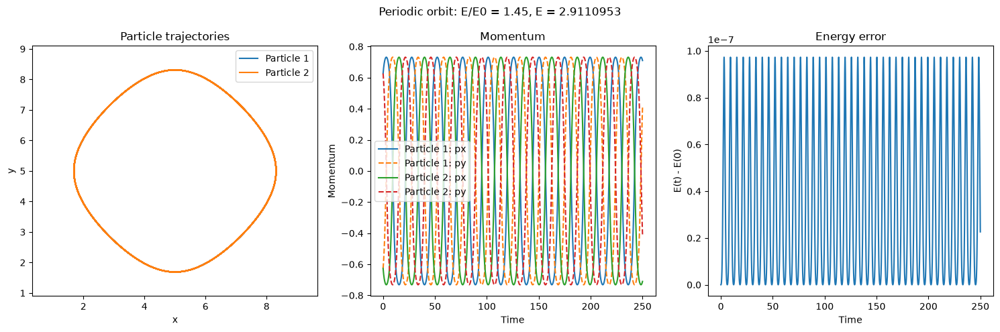


E = 3.0114779475
    Newton  0: ||P(z)-z|| = 9.791e-02
    Newton  1: ||P(z)-z|| = 3.570e-03
    Newton  2: ||P(z)-z|| = 4.009e-06
    Newton  3: ||P(z)-z|| = 1.536e-12
    fixed-point residual = 1.536e-12
    Newton iterations = 4
    lambda = [-0.25756922+0.96625986j -0.25756922-0.96625986j  0.26538361+0.9641429j
  0.26538361-0.9641429j   0.26538362+0.9641429j   0.26538362-0.9641429j ]
    |lambda| = [1.00000001 1.00000001 1.         1.         0.99999999 0.99999999]
    q* =
 [[2.81593503 2.81593503]
 [7.18406497 7.18406497]]
    p* =
 [[ 0.66042569 -0.66042569]
 [-0.66042569  0.66042569]]


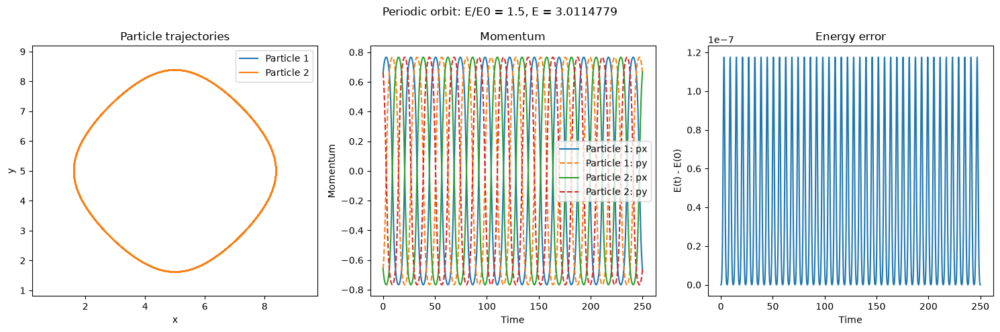


E = 3.1118605457
    Newton  0: ||P(z)-z|| = 8.287e-02
    Newton  1: ||P(z)-z|| = 2.829e-03
    Newton  2: ||P(z)-z|| = 3.129e-06
    Newton  3: ||P(z)-z|| = 1.630e-12
    fixed-point residual = 1.630e-12
    Newton iterations = 4
    lambda = [-0.19568857+0.98066609j -0.19568857-0.98066609j  0.31301014+0.94974977j
  0.31301014-0.94974977j  0.31301016+0.94974979j  0.31301016-0.94974979j]
    |lambda| = [1.         1.         0.99999999 0.99999999 1.00000001 1.00000001]
    q* =
 [[2.78160186 2.78160186]
 [7.21839814 7.21839814]]
    p* =
 [[ 0.69293845 -0.69293845]
 [-0.69293845  0.69293845]]


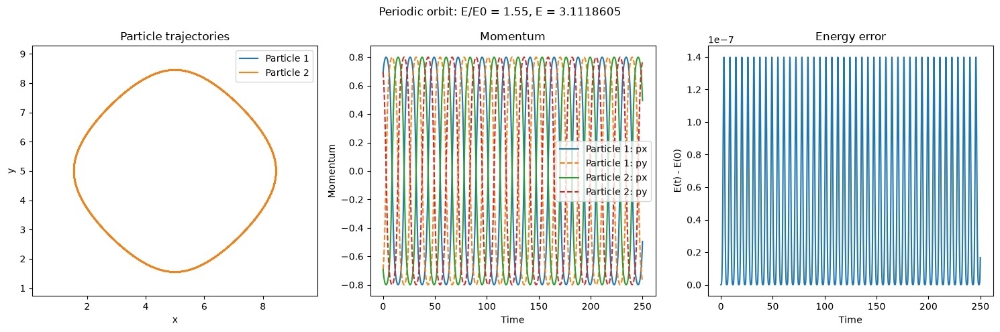


E = 3.2122431440
    Newton  0: ||P(z)-z|| = 7.076e-02
    Newton  1: ||P(z)-z|| = 2.261e-03
    Newton  2: ||P(z)-z|| = 2.406e-06
    Newton  3: ||P(z)-z|| = 1.694e-12
    fixed-point residual = 1.694e-12
    Newton iterations = 4
    lambda = [-0.14129391+0.9899677j  -0.14129391-0.9899677j   0.35421475+0.9351641j
  0.35421475-0.9351641j   0.35421474+0.93516409j  0.35421474-0.93516409j]
    |lambda| = [1.00000001 1.00000001 0.99999999 0.99999999 0.99999998 0.99999998]
    q* =
 [[2.75091224 2.75091224]
 [7.24908776 7.24908776]]
    p* =
 [[ 0.72428858 -0.72428858]
 [-0.72428858  0.72428858]]


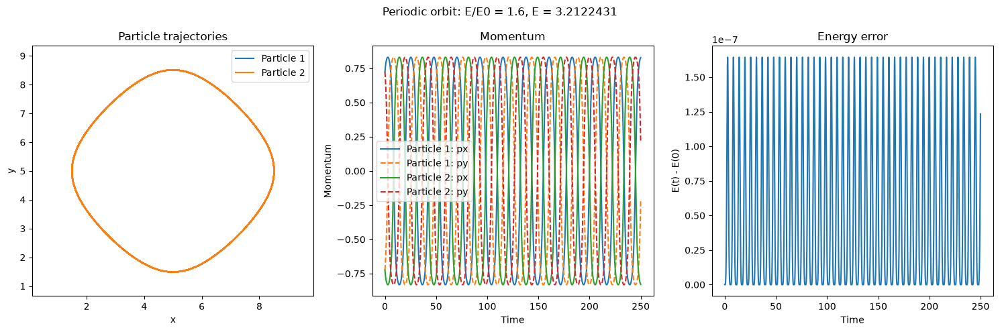


E = 3.3126257422
    Newton  0: ||P(z)-z|| = 6.089e-02
    Newton  1: ||P(z)-z|| = 1.821e-03
    Newton  2: ||P(z)-z|| = 1.828e-06
    Newton  3: ||P(z)-z|| = 1.295e-12
    fixed-point residual = 1.295e-12
    Newton iterations = 4
    lambda = [-0.09296895+0.995669j   -0.09296895-0.995669j    0.39032266+0.92067813j
  0.39032266-0.92067813j  0.39032265+0.92067812j  0.39032265-0.92067812j]
    |lambda| = [0.99999999 0.99999999 1.         1.         0.99999999 0.99999999]
    q* =
 [[2.72335302 2.72335302]
 [7.27664698 7.27664698]]
    p* =
 [[ 0.75460212 -0.75460212]
 [-0.75460212  0.75460212]]


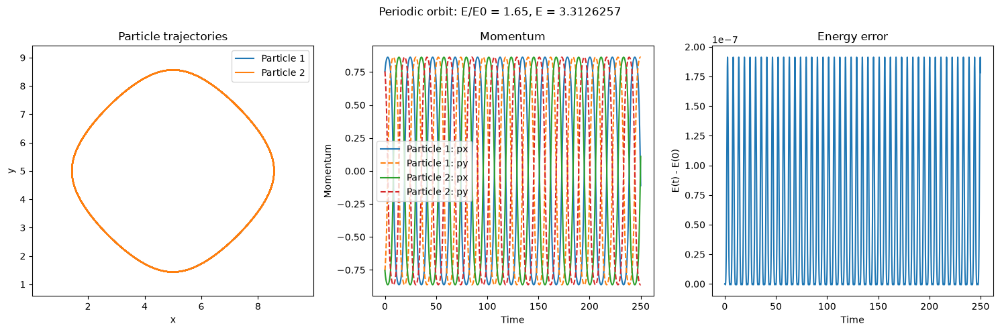


E = 3.4130083405
    Newton  0: ||P(z)-z|| = 5.275e-02
    Newton  1: ||P(z)-z|| = 1.477e-03
    Newton  2: ||P(z)-z|| = 1.377e-06
    Newton  3: ||P(z)-z|| = 1.160e-12
    fixed-point residual = 1.160e-12
    Newton iterations = 4
    lambda = [-0.04963456+0.99876745j -0.04963456-0.99876745j  0.42230411+0.9064542j
  0.42230411-0.9064542j   0.4223041 +0.90645422j  0.4223041 -0.90645422j]
    |lambda| = [1.00000001 1.00000001 0.99999999 0.99999999 1.         1.        ]
    q* =
 [[2.69850413 2.69850413]
 [7.30149587 7.30149587]]
    p* =
 [[ 0.78398142 -0.78398142]
 [-0.78398142  0.78398142]]


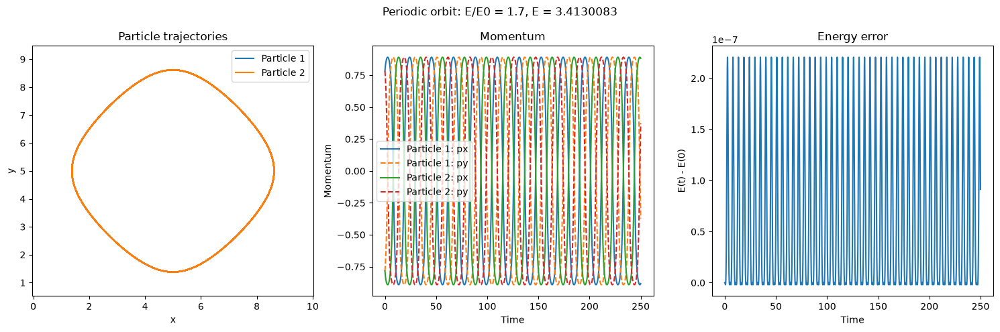


E = 3.5133909387
    Newton  0: ||P(z)-z|| = 4.597e-02
    Newton  1: ||P(z)-z|| = 1.204e-03
    Newton  2: ||P(z)-z|| = 1.032e-06
    Newton  3: ||P(z)-z|| = 9.131e-13
    fixed-point residual = 9.131e-13
    Newton iterations = 4
    lambda = [-0.01045808+0.99994531j -0.01045808-0.99994531j  0.45088712+0.89258097j
  0.45088712-0.89258097j  0.45088714+0.89258099j  0.45088714-0.89258099j]
    |lambda| = [1.         1.         0.99999999 0.99999999 1.00000002 1.00000002]
    q* =
 [[2.67601757 2.67601757]
 [7.32398243 7.32398243]]
    p* =
 [[ 0.81251121 -0.81251121]
 [-0.81251121  0.81251121]]


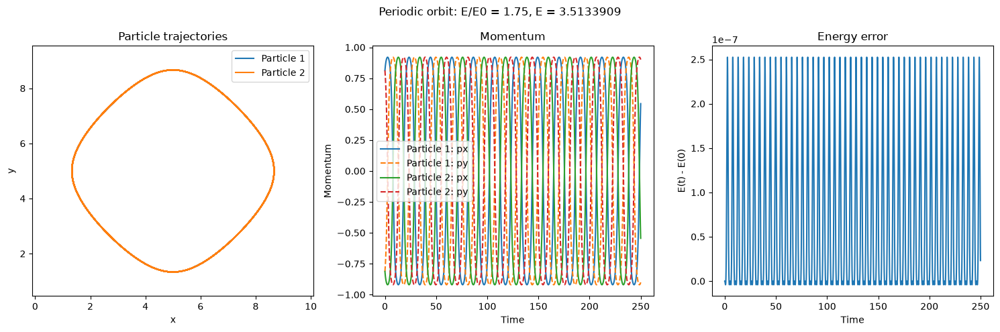


E = 3.6137735370
    Newton  0: ||P(z)-z|| = 4.027e-02
    Newton  1: ||P(z)-z|| = 9.874e-04
    Newton  2: ||P(z)-z|| = 7.702e-07
    Newton  3: ||P(z)-z|| = 4.709e-13
    fixed-point residual = 4.709e-13
    Newton iterations = 4
    lambda = [0.0252115 +0.99968213j 0.0252115 -0.99968213j 0.47662994+0.87910403j
 0.47662994-0.87910403j 0.47662995+0.87910404j 0.47662995-0.87910404j]
    |lambda| = [0.99999999 0.99999999 1.         1.         1.00000001 1.00000001]
    q* =
 [[2.65560221 2.65560221]
 [7.34439779 7.34439779]]
    p* =
 [[ 0.84026284 -0.84026284]
 [-0.84026284  0.84026284]]


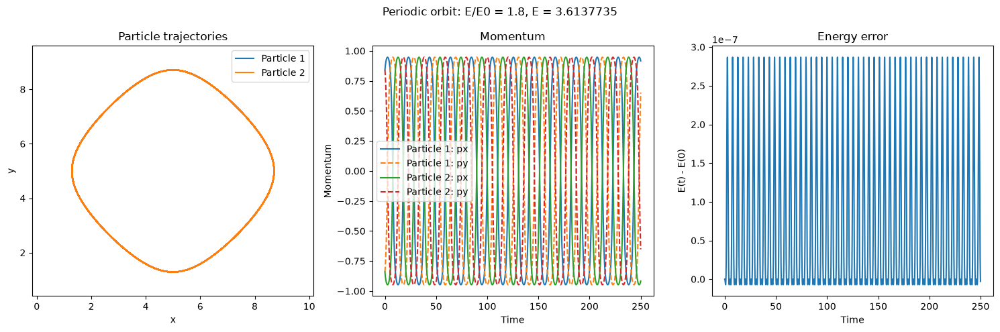


E = 3.7141561352
    Newton  0: ||P(z)-z|| = 3.545e-02
    Newton  1: ||P(z)-z|| = 8.135e-04
    Newton  2: ||P(z)-z|| = 5.734e-07
    Newton  3: ||P(z)-z|| = 3.381e-13
    fixed-point residual = 3.381e-13
    Newton iterations = 4
    lambda = [0.0578901 +0.99832295j 0.0578901 -0.99832295j 0.49996877+0.86604343j
 0.49996877-0.86604343j 0.49996875+0.86604344j 0.49996875-0.86604344j]
    |lambda| = [0.99999999 0.99999999 1.         1.         1.         1.        ]
    q* =
 [[2.63701236 2.63701236]
 [7.36298764 7.36298764]]
    p* =
 [[ 0.86729722 -0.86729722]
 [-0.86729722  0.86729722]]


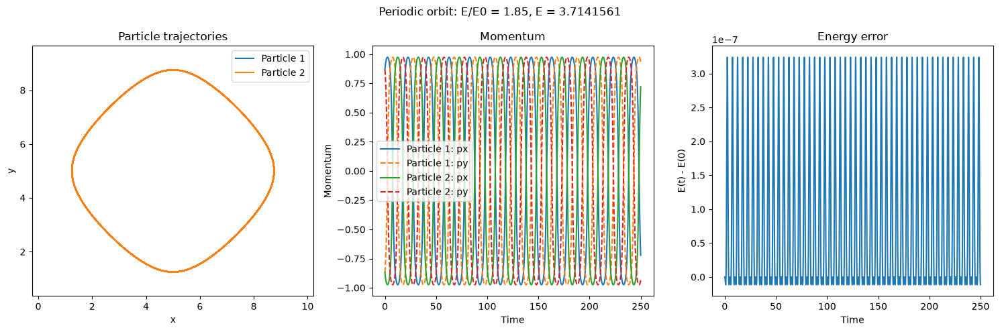


E = 3.8145387335
    Newton  0: ||P(z)-z|| = 3.134e-02
    Newton  1: ||P(z)-z|| = 6.732e-04
    Newton  2: ||P(z)-z|| = 4.264e-07
    Newton  3: ||P(z)-z|| = 2.863e-13
    fixed-point residual = 2.863e-13
    Newton iterations = 4
    lambda = [0.08799194+0.99612115j 0.08799194-0.99612115j 0.52125019+0.8534039j
 0.52125019-0.8534039j  0.52125019+0.85340392j 0.52125019-0.85340392j]
    |lambda| = [0.99999997 0.99999997 0.99999999 0.99999999 1.00000001 1.00000001]
    q* =
 [[2.62003905 2.62003905]
 [7.37996095 7.37996095]]
    p* =
 [[ 0.89366699 -0.89366699]
 [-0.89366699  0.89366699]]


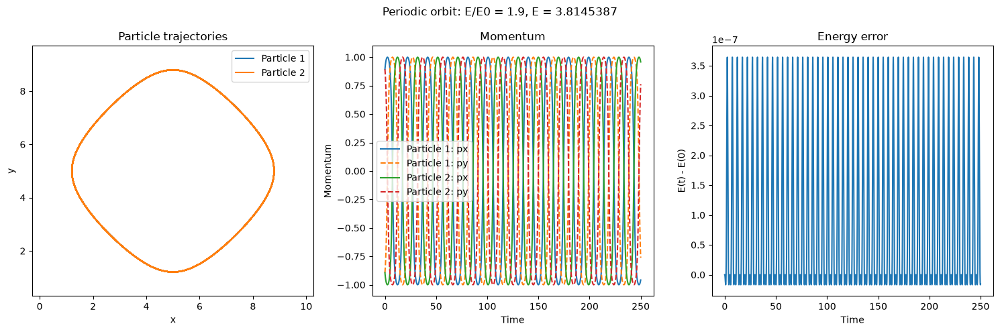


E = 3.9149213317
    Newton  0: ||P(z)-z|| = 2.781e-02
    Newton  1: ||P(z)-z|| = 5.594e-04
    Newton  2: ||P(z)-z|| = 3.169e-07
    Newton  3: ||P(z)-z|| = 2.033e-13
    fixed-point residual = 2.033e-13
    Newton iterations = 4
    lambda = [0.11585361+0.99326628j 0.11585361-0.99326628j 0.54075372+0.84118093j
 0.54075372-0.84118093j 0.54075376+0.84118096j 0.54075376-0.84118096j]
    |lambda| = [0.99999998 0.99999998 0.99999997 0.99999997 1.00000002 1.00000002]
    q* =
 [[2.60450338 2.60450338]
 [7.39549662 7.39549662]]
    p* =
 [[ 0.91941812 -0.91941812]
 [-0.91941812  0.91941812]]


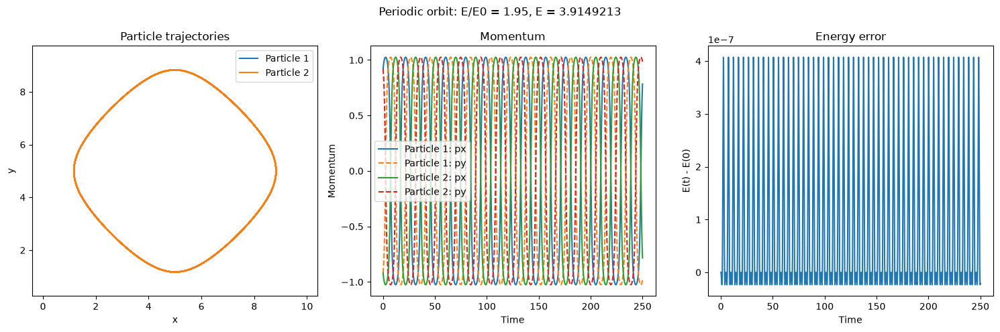


E = 4.0153039300
    Newton  0: ||P(z)-z|| = 2.477e-02
    Newton  1: ||P(z)-z|| = 4.666e-04
    Newton  2: ||P(z)-z|| = 2.356e-07
    Newton  3: ||P(z)-z|| = 1.323e-13
    fixed-point residual = 1.323e-13
    Newton iterations = 4
    lambda = [0.14175172+0.98990223j 0.14175172-0.98990223j 0.55870776+0.82936462j
 0.55870776-0.82936462j 0.55870778+0.82936457j 0.55870778-0.82936457j]
    |lambda| = [0.99999999 0.99999999 1.00000001 1.00000001 0.99999999 0.99999999]
    q* =
 [[2.59025123 2.59025123]
 [7.40974877 7.40974877]]
    p* =
 [[ 0.94459115 -0.94459115]
 [-0.94459115  0.94459115]]


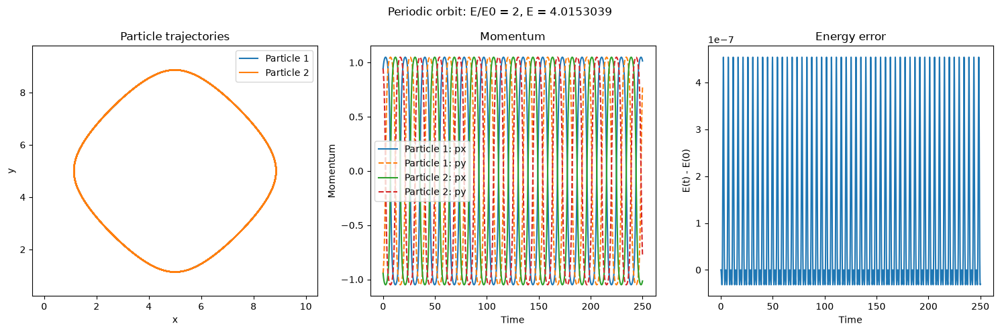

In [3]:
a = 3.6644771408428354  # found by calculating the gradient of V and set it to 0
A = 0.001  # deviation from the exact equilibrium (stationary potential) point
q0 = [
    [a + A / 2, a + A / 2],
    [10 - a - A / 2, 10 - a - A / 2],
]  # initial position
p0 = [
    [0.1, -0.1],
    [-0.1, 0.1],
]  # initial momentum

parameters = dict(k=1.0, alpha=1.0, beta=1.0, C=1.0, Lx=10.0, Ly=10.0)

# Keep the report01 case3 state above as the energy reference. Direct Newton
# from it stalls; this nearby symmetric seed was found at the SAME energy.
# This seed is specific to case3 and the parameters above.
energy0 = kinetic(np.asarray(p0), [1, 1]) + inverse_power_potential(np.asarray(q0), **parameters)
b = 3.6
q_guess = np.array([[b, b], [10 - b, 10 - b]])
v = np.sqrt((energy0 - inverse_power_potential(q_guess, **parameters)) / 2)
p_guess = np.array([[v, -v], [-v, v]])

results = continue_to_periodic_orbit(
    initial_condition={"q": q_guess, "p": p_guess},
    parameters=parameters,
    section=Section(normal=(1, -1), value=0.0, direction=1),
    energy_ratios=np.array([
        1.00, 1.05, 1.10, 1.15, 1.20, 1.25, 1.30, 1.35, 1.40, 1.45, 1.50, 1.55, 1.60,
        1.65, 1.70, 1.75, 1.80, 1.85, 1.90, 1.95, 2.00
    ]),
    h=0.0025,
    max_return_steps=100000,
    nsteps=100000,
)

**Result.** Newton converges at every energy from $E \approx 2.01$ to $E \approx 4.02$, and **all multipliers stay on the unit circle, so the whole family is linearly stable**. As the energy increases, the crossing point moves outward along the diagonal (from $(3.59, 3.59)$ to $(2.59, 2.59)$), so the loop grows towards the walls.

## 3. The same family at much higher energy

Starting from the last orbit above, we raise the momentum to $\pm5$ and correct at that single energy (`energy_ratios=[1.0]`).

initial energy: 52.2307990669
energy ratios: [1.]

E = 52.2307990669
    Newton  0: ||P(z)-z|| = 2.029e-02
    Newton  1: ||P(z)-z|| = 3.478e-03
    Newton  2: ||P(z)-z|| = 9.657e-06
    Newton  3: ||P(z)-z|| = 1.646e-09
    Newton  4: ||P(z)-z|| = 5.651e-13
    fixed-point residual = 5.651e-13
    Newton iterations = 5
    lambda = [0.93737979+0.34830888j 0.93737979-0.34830888j 0.98211103+0.18830268j
 0.98211103-0.18830268j 0.98211099+0.18830294j 0.98211099-0.18830294j]
    |lambda| = [0.99999998 0.99999998 0.99999999 0.99999999 1.         1.        ]
    q* =
 [[2.4442528 2.4442528]
 [7.5557472 7.5557472]]
    p* =
 [[ 4.99632726 -4.99632726]
 [-4.99632726  4.99632726]]


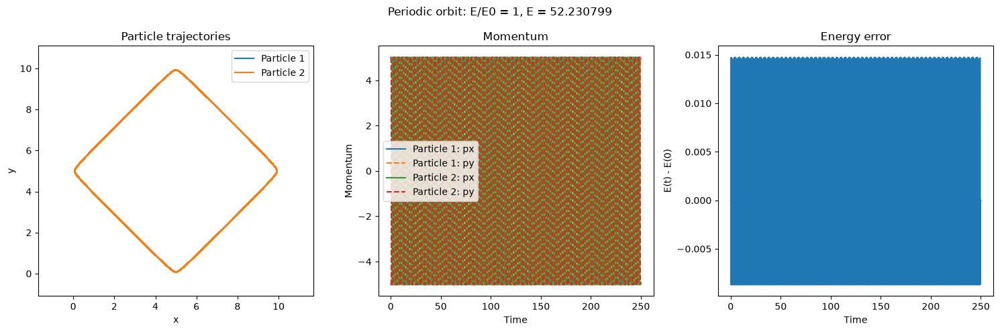

In [4]:
q_guess = [[2.59025123, 2.59025123],
 [7.40974877, 7.40974877]]
p_guess = [[5, -5],
 [-5,  5]]

parameters = dict(k=1.0, alpha=1.0, beta=1.0, C=1.0, Lx=10.0, Ly=10.0)

results = continue_to_periodic_orbit(
    initial_condition={"q": q_guess, "p": p_guess},
    parameters=parameters,
    section=Section(normal=(1, -1), value=0.0, direction=1),
    energy_ratios=[1.00],
    h=0.0025,  # Validated against h=0.005; period is about 101.82.
    max_return_steps=100000,  # Must allow at least one period: h * steps > 102.
    nsteps=100000,
)

**Result ($E \approx 52$):** Newton converges in 5 iterations. The orbit is now a **diamond** that runs almost into the middle of each wall, and it is still stable (all $|\lambda| = 1$).

Next, momentum $\pm10$ ($E \approx 202$) with a much smaller step $h = 10^{-5}$.

initial energy: 202.2307990669
energy ratios: [1.]

E = 202.2307990669
    Newton  0: ||P(z)-z|| = 4.991e-03
    Newton  1: ||P(z)-z|| = 4.908e-04
    Newton  2: ||P(z)-z|| = 6.414e-08
    Newton  3: ||P(z)-z|| = 9.678e-12
    fixed-point residual = 9.678e-12
    Newton iterations = 4
    lambda = [0.98403403+0.17797721j 0.98403403-0.17797721j 0.99582538+0.09131721j
 0.99582538-0.09131721j 0.99581921+0.09131624j 0.99581921-0.09131624j]
    |lambda| = [0.99999943 0.99999943 1.00000351 1.00000351 0.99999728 0.99999728]
    q* =
 [[2.47863945 2.47863945]
 [7.52136055 7.52136055]]
    p* =
 [[ 9.99862412 -9.99862412]
 [-9.99862412  9.99862412]]


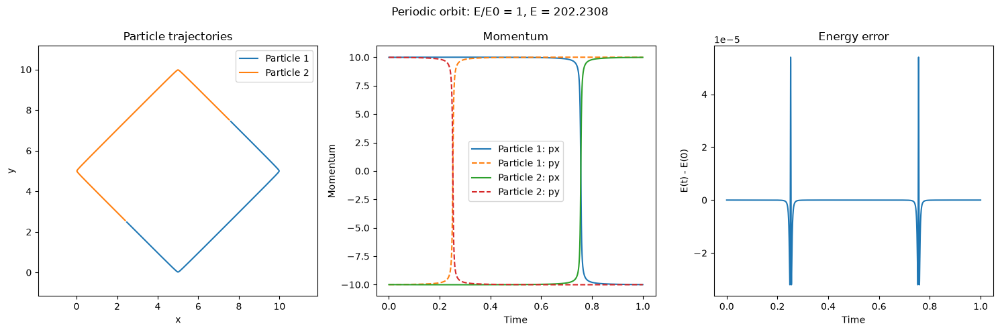

In [5]:
q_guess = [[2.59025123, 2.59025123],
 [7.40974877, 7.40974877]]
p_guess = [[10, -10],
 [-10,  10]]

parameters = dict(k=1.0, alpha=1.0, beta=1.0, C=1.0, Lx=10.0, Ly=10.0)

results = continue_to_periodic_orbit(
    initial_condition={"q": q_guess, "p": p_guess},
    parameters=parameters,
    section=Section(normal=(1, -1), value=0.0, direction=1),
    energy_ratios=[1.00],
    h=0.00001,  # Validated against h=0.005; period is about 101.82.
    max_return_steps=1000000,  # Must allow at least one period: h * steps > 102.
    nsteps=100000,
)

**Result ($E \approx 202$):** Newton converges again and the orbit is still stable (all $|\lambda| = 1$ to within about $4\times10^{-6}$, which is the finite-difference accuracy at this step size).

## 4. The Case 3 family towards lower energy

Finally we start from the same Case 3 seed and lower the energy in small steps of $0.1\%$.

initial energy: 2.0076519650
energy ratios: [1.    0.999 0.998 0.997 0.996 0.995]

E = 2.0076519650
    Newton  0: ||P(z)-z|| = 2.744e-02
    Newton  1: ||P(z)-z|| = 6.962e-04
    Newton  2: ||P(z)-z|| = 3.991e-07
    Newton  3: ||P(z)-z|| = 1.121e-13
    fixed-point residual = 1.121e-13
    Newton iterations = 4
    lambda = [-0.22062348+0.97535906j -0.22062348-0.97535906j -0.78095788+0.62458371j
 -0.78095788-0.62458371j -0.78095787+0.62458371j -0.78095787-0.62458371j]
    |lambda| = [1.00000001 1.00000001 1.00000001 1.00000001 1.         1.        ]
    q* =
 [[3.5889166 3.5889166]
 [6.4110834 6.4110834]]
    p* =
 [[ 0.09652827 -0.09652827]
 [-0.09652827  0.09652827]]


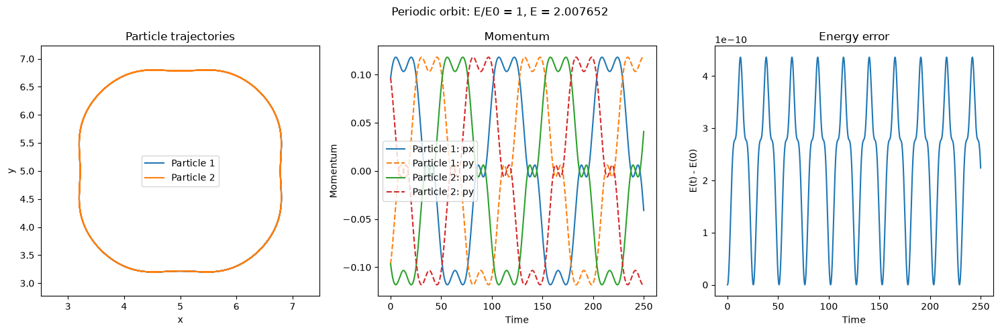


E = 2.0056443130
    Newton  0: ||P(z)-z|| = 4.163e-02
    Newton  1: ||P(z)-z|| = 8.830e-03
    Newton  2: ||P(z)-z|| = 7.572e-05
    Newton  3: ||P(z)-z|| = 2.185e-08
    Newton  4: ||P(z)-z|| = 7.653e-14
    fixed-point residual = 7.653e-14
    Newton iterations = 5
    lambda = [-0.09060599+0.99588683j -0.09060599-0.99588683j  0.65166289+0.75850871j
  0.65166289-0.75850871j  0.65166289+0.75850872j  0.65166289-0.75850872j]
    |lambda| = [1.00000001 1.00000001 0.99999999 0.99999999 1.         1.        ]
    q* =
 [[3.60744502 3.60744502]
 [6.39255498 6.39255498]]
    p* =
 [[ 0.09276347 -0.09276347]
 [-0.09276347  0.09276347]]


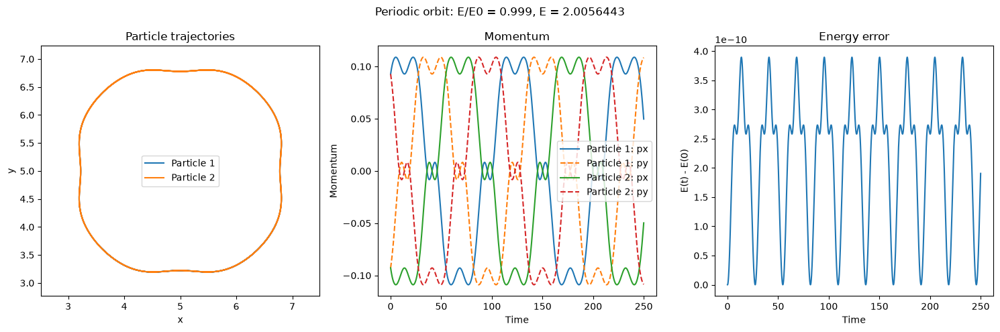


E = 2.0036366611
    Newton  0: ||P(z)-z|| = 2.274e-01
    Newton  1: ||P(z)-z|| = 5.252e-02
    Newton  2: ||P(z)-z|| = 8.701e-03
    Newton  3: ||P(z)-z|| = 6.392e-05
    Newton  4: ||P(z)-z|| = 4.564e-08
    Newton  5: ||P(z)-z|| = 3.501e-13
    fixed-point residual = 3.501e-13
    Newton iterations = 6
    lambda = [-5.26945355+0.j         -0.18977298+0.j          0.35572744+0.93458975j
  0.35572744-0.93458975j -0.04882642+0.99880727j -0.04882642-0.99880727j]
    |lambda| = [5.26945355 0.18977298 1.         1.         0.99999999 0.99999999]
    q* =
 [[3.56602701 3.56602701]
 [6.43397299 6.43397299]]
    p* =
 [[ 0.09875273 -0.0627144 ]
 [-0.09875273  0.0627144 ]]


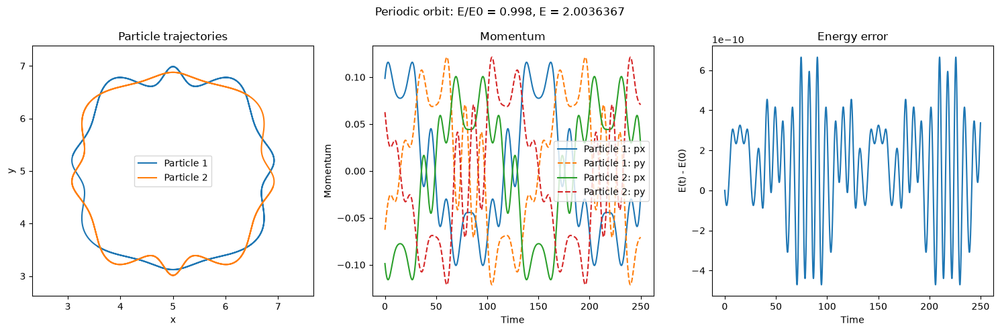


E = 2.0016290091
    Newton  0: ||P(z)-z|| = 1.200e-02
    Newton  1: ||P(z)-z|| = 4.224e-03
    Newton  2: ||P(z)-z|| = 8.958e-04
    Newton  3: ||P(z)-z|| = 7.980e-04
    Newton  4: ||P(z)-z|| = 2.256e-05
    Newton  5: ||P(z)-z|| = 3.035e-08
    Newton  6: ||P(z)-z|| = 1.389e-13
    fixed-point residual = 1.389e-13
    Newton iterations = 7
    lambda = [0.8451424 +0.53454153j 0.8451424 -0.53454153j 0.93411731+0.35696619j
 0.93411731-0.35696619j 0.97964725+0.20072684j 0.97964725-0.20072684j]
    |lambda| = [1.00000016 1.00000016 1.         1.         1.         1.        ]
    q* =
 [[3.5640195 3.5640195]
 [6.4359805 6.4359805]]
    p* =
 [[ 0.09222675 -0.05548475]
 [-0.09222675  0.05548475]]


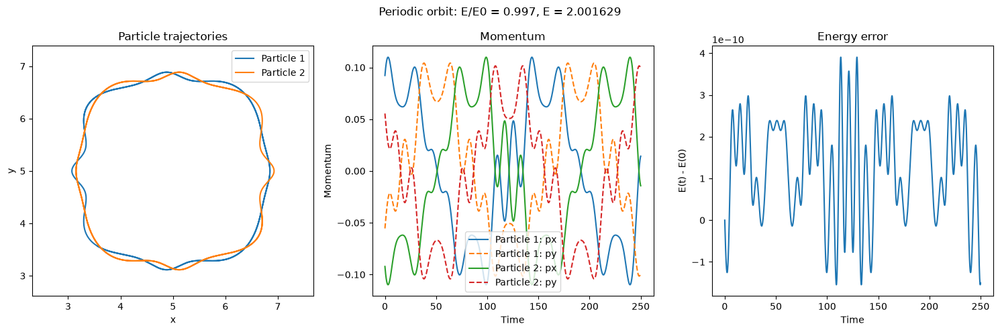


E = 1.9996213571
    Newton  0: ||P(z)-z|| = 1.868e-01
    Newton  1: ||P(z)-z|| = 9.667e-02
    Newton  2: ||P(z)-z|| = 5.908e-02
    Newton  3: ||P(z)-z|| = 5.897e-02
    Newton  4: ||P(z)-z|| = 5.887e-02
    Newton  5: ||P(z)-z|| = 5.878e-02
    Newton  6: ||P(z)-z|| = 5.869e-02
    Newton  7: ||P(z)-z|| = 5.860e-02
    Newton  8: ||P(z)-z|| = 5.852e-02
    Newton  9: ||P(z)-z|| = 5.844e-02
    Newton 10: ||P(z)-z|| = 5.837e-02


RuntimeError: Newton did not converge after 10 updates

In [6]:
a = 3.6644771408428354  # found by calculating the gradient of V and set it to 0
A = 0.001  # deviation from the exact equilibrium (stationary potential) point
q0 = [
    [a + A / 2, a + A / 2],
    [10 - a - A / 2, 10 - a - A / 2],
]  # initial position
p0 = [
    [0.1, -0.1],
    [-0.1, 0.1],
]  # initial momentum

parameters = dict(k=1.0, alpha=1.0, beta=1.0, C=1.0, Lx=10.0, Ly=10.0)

# Keep the report01 case3 state above as the energy reference. Direct Newton
# from it stalls; this nearby symmetric seed was found at the SAME energy.
# This seed is specific to case3 and the parameters above.
energy0 = kinetic(np.asarray(p0), [1, 1]) + inverse_power_potential(np.asarray(q0), **parameters)
b = 3.6
q_guess = np.array([[b, b], [10 - b, 10 - b]])
v = np.sqrt((energy0 - inverse_power_potential(q_guess, **parameters)) / 2)
p_guess = np.array([[v, -v], [-v, v]])

results = continue_to_periodic_orbit(
    initial_condition={"q": q_guess, "p": p_guess},
    parameters=parameters,
    section=Section(normal=(1, -1), value=0.0, direction=1),
    energy_ratios=np.array([
        1.00, 0.999, 0.998, 0.997, 0.996, 0.995
    ]),
    h=0.0025,
    max_return_steps=100000,
    nsteps=100000,
)

**Result.** Continuing to lower energy is unreliable:

| $E/E_0$ | What Newton found |
|---|---|
| 1.000 | the symmetric loop, stable |
| 0.999 | symmetric loop, stable |
| 0.998 | a **different, asymmetric** orbit ($p_{x1} \ne -p_{y1}$) that is **unstable** ($\lambda \approx -5.27$) |
| 0.997 | another asymmetric orbit, stable |
| 0.996 | **Newton fails**: the residual stops decreasing at about $0.06$ |

Just below $E_0$ several periodic orbits lie very close together, and Newton jumps between them. Following the symmetric family further down would need smaller steps or a continuation method that tracks the branch (for example pseudo-arclength continuation).

## Summary

- The Newton + Poincaré-map method finds periodic orbits reliably from rough guesses. Residuals are typically $10^{-12}$ after 3–5 iterations.
- **Vertical (Case 4) orbit:** stable for $E \gtrsim 3.9$ and unstable around $E \approx 2.7$–$3.3$. At lower energy Newton moves to a different, S-shaped orbit.
- **Circular (Case 3) orbit:** stable over the whole range tested, $E \approx 2$ to $E \approx 202$. It grows from a small loop into a diamond that nearly touches all four walls.
- Just below the Case 3 energy the family is hard to follow because nearby orbits get mixed up.